# -------MNIST----------

In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [3]:
data_path = os.path.expanduser('~/MNIST')

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root=data_path,
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root=data_path,
    train=False,
    download=True,
    transform=transform

)

image, label = train_dataset[0]
print(len(train_dataset), image.shape, label)
print(len(test_dataset))




60000 torch.Size([1, 28, 28]) 5
10000


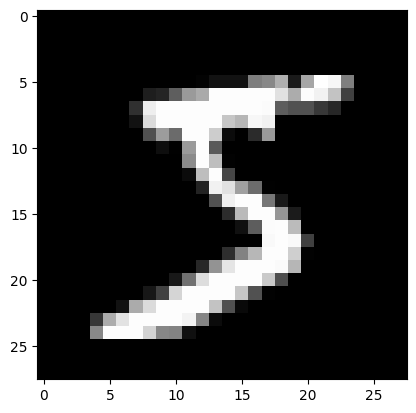

In [4]:
plt.imshow(image.squeeze(), cmap='gray')
plt.show()

In [5]:
loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
images, labels = next(iter(loader))
print(images.shape, labels.shape)

torch.Size([32, 1, 28, 28]) torch.Size([32])


In [6]:
flat_images = images.flatten(start_dim=1)
print(flat_images.shape)

torch.Size([32, 784])


In [44]:
#layer = torch.nn.Linear(784, 10) #Create randomized weights. 

layer = torch.nn.Sequential(
    torch.nn.Linear(784,128),
    torch.nn.ReLU(),
    torch.nn.Linear(128,10)

)

scores = layer(flat_images)
print(scores.shape)

torch.Size([32, 10])


In [45]:
print(layer[0].weight.shape)
print(layer[0].bias.shape)
print(layer[0].weight[0, :10])

torch.Size([128, 784])
torch.Size([128])
tensor([ 0.0251,  0.0089, -0.0006,  0.0068,  0.0312,  0.0060, -0.0297, -0.0213,
         0.0252, -0.0152], grad_fn=<SliceBackward0>)


In [46]:
predictions = scores.argmax(dim=1)
print('Guess: ', predictions[1].item())
print('Correct: ', labels[1].item())

Guess:  1
Correct:  8


In [47]:
predictions = scores.argmax(dim=1)
accuracy = (predictions == labels).float().mean()

print(accuracy.item())

0.03125


### Go through one epoch

In [76]:

loss_fn = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(layer.parameters(), lr = 0.01)


def train_model():
    layer.train()
    total_loss = 0
    for batch_num, (images, labels) in enumerate(loader):
        
        
        flat_images = images.flatten(start_dim=1)
        scores = layer(flat_images)

        loss = loss_fn(scores, labels)

        total_loss += loss.item() * labels.size(0)

        optimizer.zero_grad() # Clean of old gradiens, for a new batch. 
        loss.backward() # Backwards prop to get gradient    
        optimizer.step() # Update weights with

    return total_loss / len(loader.dataset)


In [77]:
labels.size()

torch.Size([32])

In [78]:
predictions = scores.argmax(dim=1) ## Last batch to see accuracy. 
accuracy = (predictions == labels).float().mean()

print(accuracy.item())

0.03125


### Test data

In [79]:
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False) # Creates a loader that batches 10k pics into batches of 32. 

In [80]:


def evaluate_model():
    layer.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            flat_images = images.flatten(start_dim=1)
            scores = layer(flat_images)
            predictions = scores.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total   += labels.size(0)
    accuracy = correct/total
    return accuracy

In [81]:
results = []
loss_results = []

epochs = 10
for i in range(epochs):
    tot_loss = train_model()
    accuracy = evaluate_model()

    loss_results.append(tot_loss)
    results.append(accuracy)

results_df = pd.DataFrame({
    'epoch'     :np.arange(1,epochs + 1),
    'accuracy'  :results,
    'loss'      :loss_results
})

results_df

,epoch,accuracy,loss
0,1,0.9717,0.083891
1,2,0.9709,0.081577
2,3,0.9720,0.079320
3,4,0.9728,0.077336
4,5,0.9727,0.075260
5,6,0.9724,0.073489
6,7,0.9735,0.071538
7,8,0.9738,0.069810
8,9,0.9735,0.068109
9,10,0.9748,0.066564


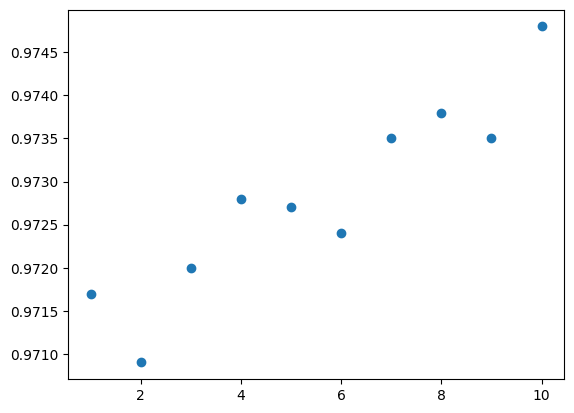

In [82]:

plt.scatter(
    x=results_df['epoch'],
    y = results_df['accuracy'],

    )

In [83]:
results_df['accuracy'].max()

np.float64(0.9748)

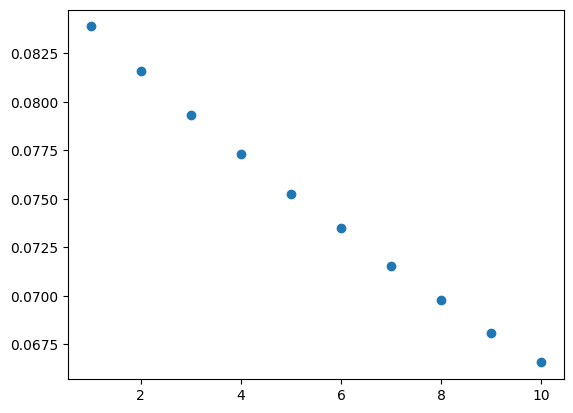

In [84]:
plt.scatter(
    x=results_df['epoch'],
    y=results_df['loss']
)